# Reconhecimento Óptico de Caracteres (OCR) em imagens com OpenCV e Tesseract

- **Repositório:** `visao-computacional-ocr`  
- **Tecnologias:** OpenCV, pytesseract  
- **Arquivo Original:** `Untitled2.ipynb`  

---


# Curso de OCR com OpenCV e Tesseract

Este notebook é um curso prático e progressivo sobre Optical Character Recognition (OCR), utilizando as bibliotecas OpenCV e Tesseract no ambiente Google Colab. O objetivo é que você compreenda desde os fundamentos matemáticos e conceituais da visão computacional aplicada ao OCR até a implementação, segmentação, reconhecimento, e a integração entre OpenCV e Tesseract.

Cada conceito importante será acompanhado de um exemplo prático e visual, com explicações claras antes e depois do código. Os experimentos visam permitir que você observe o impacto de diferentes parâmetros e técnicas.

---

## Regras Gerais do Notebook

*   **Ambiente:** Desenvolvido para funcionar no Google Colab.
*   **Linguagem:** Utiliza Python.
*   **Foco:** Prioriza código executável e experimentos visuais. Sempre que possível, imagens intermediárias serão geradas para visualização.
*   **Transparência:** Etapas importantes não serão escondidas atrás de funções abstratas.
*   **Didática:** Explicações claras e concisas precedem o código, e os resultados são discutidos após a execução.
*   **Comentários:** O código é bem comentado em inglês.
*   **Idioma:** Textos explicativos destinados ao estudante estão em português brasileiro.
*   **Estrutura:** Usa Markdown para organizar o conteúdo como uma aula.
*   **Interatividade:** Incluirá exercícios práticos e experimentos para alterar parâmetros.

---

## Sumário dos Módulos

1.  Introdução ao OCR
2.  Como uma imagem é representada
3.  Fundamentos de visão computacional com OpenCV
4.  Pré-processamento para OCR
5.  Instalação e funcionamento do Tesseract
6.  Primeiro OCR
7.  Page Segmentation Mode (PSM)
8.  Segmentação e localização do texto
9.  Como o Tesseract reconhece caracteres
10. Perceptron (Implementação do zero)
11. LSTM (Conceitos e intuição)
12. CTC (Connectionist Temporal Classification)
13. Arquitetura moderna do Tesseract
14. OpenCV + Tesseract (Pipelines)
15. Detecção de texto versus OCR
16. OCR em screenshots
17. OCR em documentos
18. Tabelas e gráficos (Limitações do OCR)
19. Avaliação de OCR (Métricas)
20. Fine-tuning / treinamento do Tesseract
21. Dados sintéticos para OCR
22. Pipeline profissional
23. Comparação com modelos modernos
24. Projeto final
25. Exercícios
26. Experimentos obrigatórios

## Instalação das Bibliotecas Necessárias

Para este curso, precisaremos instalar algumas bibliotecas Python. O `opencv-python-headless` é uma versão do OpenCV sem dependências de GUI, ideal para ambientes como o Colab. O `pytesseract` é a interface Python para o Tesseract OCR Engine.



In [1]:
# Install necessary libraries
!sudo apt install tesseract-ocr
!pip install pytesseract opencv-python-headless matplotlib numpy

import cv2
import pytesseract
import matplotlib.pyplot as plt
import numpy as np

print("Libraries installed and imported successfully!")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
0 upgraded, 0 newly installed, 0 to remove and 1 not upgraded.
  Using cached pytesseract-0.3.13-py3-none-any.whl.metadata (11 kB)
Using cached pytesseract-0.3.13-py3-none-any.whl (14 kB)
Libraries installed and imported successfully!


# Módulo 1 — Introdução ao OCR

Neste módulo, vamos entender o que é OCR, suas aplicações, e como ele se diferencia de outras tarefas de visão computacional. Vamos também explorar o pipeline geral do OCR.

## O que é OCR?

**OCR (Optical Character Recognition)**, ou Reconhecimento Óptico de Caracteres, é a tecnologia que permite converter diferentes tipos de documentos, como documentos escaneados, PDFs ou imagens com texto (como fotos de placas ou screenshots), em dados editáveis e pesquisáveis. Em essência, é o processo de transformar texto de imagens em texto digital que pode ser manipulado por softwares.

### OCR versus Visão Computacional

A **Visão Computacional** é um campo amplo da Inteligência Artificial que capacita computadores a 'ver' e interpretar imagens e vídeos. O OCR é uma *subárea* da visão computacional, focada especificamente no reconhecimento de texto. Enquanto a visão computacional pode envolver detecção de objetos, segmentação de imagens, reconhecimento facial e muitas outras tarefas, o OCR se concentra na identificação e extração de caracteres alfanuméricos e símbolos.

### Diferença entre OCR e Classificação de Imagens

**Classificação de Imagens** é a tarefa de atribuir uma única etiqueta de classe a uma imagem inteira (ex: 'esta imagem contém um gato'). O OCR, por outro lado, vai além da simples classificação. Ele precisa *localizar* e *identificar* cada caractere individualmente e, em seguida, montar esses caracteres em palavras e frases, preservando a ordem e o contexto do texto na imagem.

### OCR versus Detecção de Objetos

**Detecção de Objetos** identifica a presença e a localização de múltiplos objetos em uma imagem, desenhando 'bounding boxes' ao redor deles e atribuindo uma classe (ex: 'há um carro aqui', 'há uma pessoa ali'). Embora o OCR use bounding boxes para localizar texto, seu objetivo final não é apenas dizer 'há texto aqui', mas sim *qual* é esse texto. O texto em si é o 'objeto' de interesse, mas o reconhecimento do seu conteúdo é a etapa crucial.

### OCR versus Modelos Multimodais

**Modelos Multimodais** são sistemas de IA que podem processar e entender informações de múltiplas modalidades (ex: texto, imagem, áudio) de forma integrada. Enquanto o OCR converte imagem para texto, um modelo multimodal pode, por exemplo, entender o contexto de uma imagem e o texto nela contido para responder a uma pergunta complexa sobre ambos. O OCR fornece a entrada textual para muitos desses modelos multimodais.

### Aplicações Reais de OCR

O OCR tem uma vasta gama de aplicações práticas:

*   **Digitalização de Documentos:** Converter pilhas de documentos físicos em arquivos digitais pesquisáveis.
*   **Automação de Processos:** Extração de dados de faturas, recibos, formulários para automação de entrada de dados.
*   **Reconhecimento de Placas de Carro:** Em sistemas de estacionamento e fiscalização.
*   **Tradução em Tempo Real:** Traduzir texto em fotos (ex: Google Tradutor).
*   **Acessibilidade:** Converter texto de imagens para fala para pessoas com deficiência visual.
*   **Análise de Dados:** Extrair informações de tabelas e gráficos em documentos para análise.
*   **Segurança:** Leitura de passaportes e documentos de identificação.

## Pipeline Geral de OCR

O processo de OCR geralmente segue uma série de etapas:

### Intuição

Imagine que você recebe uma imagem. O computador precisa primeiro 'olhar' para ela, tentar encontrar onde o texto está, isolá-lo, tentar adivinhar quais letras são, e então juntar tudo para formar palavras e frases.

### Diagrama

```text
Imagem
   ↓
Pré-processamento (Melhora a qualidade da imagem para o reconhecimento)
   ↓
Detecção/Segmentação de Texto (Localiza onde o texto está na imagem)
   ↓
Reconhecimento (Identifica os caracteres e palavras)
   ↓
Texto (Saída digital)
```

## Diferença entre Text Detection, Text Segmentation, Text Recognition e Document Understanding

*   **Text Detection (Detecção de Texto):** Responde à pergunta "Onde está o texto na imagem?". O resultado é uma ou mais 'bounding boxes' (retângulos) que delimitam as regiões onde o texto está presente.

*   **Text Segmentation (Segmentação de Texto):** Vai um pouco além da detecção, separando o texto do fundo e, às vezes, até mesmo separando caracteres ou linhas individuais para facilitar o reconhecimento. Pode ser pixel a pixel (segmentação semântica) ou por componentes conectados.

*   **Text Recognition (Reconhecimento de Texto):** Responde à pergunta "Qual é o conteúdo do texto?". Após a detecção e/ou segmentação, esta etapa converte os pixels das regiões de texto em caracteres digitais. Este é o coração do OCR.

*   **Document Understanding (Compreensão de Documentos):** É uma etapa mais avançada que busca não apenas reconhecer o texto, mas também entender a estrutura e o significado do documento. Por exemplo, identificar que um texto é um 'nome de cliente' ou um 'valor total' em uma fatura. Envolve processamento de linguagem natural e modelos mais complexos.

## Exemplos de Imagens Contendo Texto

O desempenho do OCR pode variar drasticamente dependendo da qualidade e do tipo de texto na imagem. Vamos ver alguns exemplos conceituais:

*   **Texto Simples:** Texto limpo, bem impresso, com fundo uniforme (ex: página de livro escaneada).
*   **Documento:** Uma fatura, contrato, formulário com múltiplas seções, tabelas, e cabeçalhos.
*   **Screenshot:** Uma captura de tela de um software ou webpage, contendo menus, botões, ícones e texto digital.
*   **Tabela:** Dados organizados em linhas e colunas, com ou sem linhas divisórias.
*   **Gráfico:** Um gráfico de barras ou linhas onde o texto aparece como rótulos de eixos, títulos e legendas.
*   **Placa:** Texto em uma placa de rua ou de carro, que pode ter distorções, reflexos, ou estar em ângulos incomuns.
*   **Texto Inclinado:** Texto que não está perfeitamente alinhado horizontalmente.
*   **Texto com Ruído:** Texto em imagens com baixa iluminação, manchas, grãos, ou qualquer tipo de imperfeição visual.

## O que um OCR Tradicional Consegue e Não Consegue Interpretar Semanticamente

Um OCR tradicional, como o Tesseract em sua configuração básica, é excelente em *converter pixels em caracteres*. Ele consegue:

*   Reconhecer a maioria dos caracteres alfanuméricos e símbolos.
*   Reconstruir palavras e frases a partir de caracteres reconhecidos.
*   Fornecer as coordenadas (bounding boxes) do texto reconhecido.

No entanto, um OCR tradicional *não consegue* interpretar semanticamente o texto. Ele não sabe que 'CPF: 123.456.789-00' é um número de documento, ou que uma linha em uma tabela representa um 'preço unitário'. Para isso, são necessárias etapas adicionais de **Pós-processamento** e **Compreensão de Documentos**, muitas vezes envolvendo técnicas de Processamento de Linguagem Natural (PLN) ou modelos de Machine Learning especializados.

# Módulo 2 — Como uma imagem é representada

Antes de processarmos imagens para OCR, é fundamental entender como os computadores as 'enxergam'. Neste módulo, exploraremos a representação digital de imagens, utilizando conceitos básicos de pixels, cores e canais.

## Pixels, Resolução e Canais

### Intuição

Pense em uma imagem digital como uma grade muito fina, como um tabuleiro de xadrez, onde cada 'quadradinho' tem uma cor. Cada um desses quadradinhos é um **pixel** (picture element). Quanto mais quadradinhos e quanto menores eles forem, mais detalhada e nítida a imagem parecerá. A cor de cada pixel é definida por uma combinação de valores numéricos.

### Explicação

*   **Pixels:** São os menores elementos de uma imagem digital. Cada pixel armazena informações de cor e intensidade luminosa.

*   **Resolução:** Refere-se à quantidade de pixels em uma imagem, geralmente expressa como largura x altura (ex: 1920x1080 pixels). Uma resolução maior significa mais detalhes.

*   **Canais de Cor:** Para representar cores, as imagens são divididas em 'canais'. Os modelos mais comuns são RGB e BGR.
    *   **RGB (Red, Green, Blue):** Cada pixel tem um valor para a intensidade de vermelho, verde e azul. A combinação desses três valores cria a cor final do pixel. Este é o padrão mais comum para monitores e câmeras.
    *   **BGR (Blue, Green, Red):** É o formato padrão usado pelo OpenCV. É apenas uma reordenação dos canais RGB.

*   **Grayscale (Tons de Cinza):** Imagens em tons de cinza não possuem informações de cor, apenas de intensidade luminosa. Cada pixel é representado por um único valor, que varia do preto (0) ao branco (255) ou vice-versa, dependendo da convenção. É como uma imagem em preto e branco, mas com gradientes de cinza.

*   **Valores de Intensidade:** Cada canal de cor (ou o canal único em grayscale) tem um valor que geralmente varia de 0 a 255. Onde 0 representa a ausência total daquela cor/intensidade e 255 representa a intensidade máxima.
    *   Em RGB/BGR, (255, 0, 0) seria vermelho puro, (0, 0, 0) seria preto, e (255, 255, 255) seria branco.

*   **Imagens Binárias:** São o tipo mais simples de imagem, onde cada pixel só pode ter dois valores possíveis, geralmente 0 (preto) ou 255 (branco). São usadas para destacar formas ou texto de forma muito contrastada, removendo todas as nuances de cor e cinza.

## Código: Explorando a Representação da Imagem com NumPy e OpenCV

Vamos criar uma imagem de exemplo usando NumPy e ver como ela é representada. Usaremos `cv2.cvtColor` para converter entre espaços de cores e `matplotlib.pyplot.imshow` para exibir as imagens no Colab.

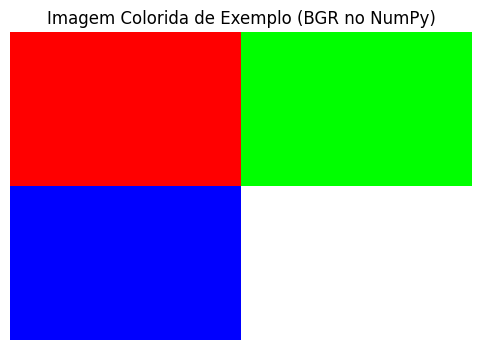

--- Propriedades da Imagem Colorida ---
Formato da imagem (altura, largura, canais): (100, 150, 3)
Tipo de dado dos pixels: uint8
Valor mínimo de pixel: 0
Valor máximo de pixel: 255


In [2]:
### Criando uma imagem de exemplo colorida

# Create a dummy colored image (height, width, channels) with NumPy
# We'll make a 100x150 pixel image
# Top-left red, top-right green, bottom-left blue, bottom-right white

img_color = np.zeros((100, 150, 3), dtype=np.uint8)

# Red (BGR: 0, 0, 255) in top-left quadrant
img_color[:50, :75, 2] = 255

# Green (BGR: 0, 255, 0) in top-right quadrant
img_color[:50, 75:, 1] = 255

# Blue (BGR: 255, 0, 0) in bottom-left quadrant
img_color[50:, :75, 0] = 255

# White (BGR: 255, 255, 255) in bottom-right quadrant
img_color[50:, 75:] = [255, 255, 255]

# Display the colored image
plt.figure(figsize=(6, 4))
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)) # Convert BGR to RGB for matplotlib display
plt.title('Imagem Colorida de Exemplo (BGR no NumPy)')
plt.axis('off')
plt.show()

print("--- Propriedades da Imagem Colorida ---")
print(f"Formato da imagem (altura, largura, canais): {img_color.shape}")
print(f"Tipo de dado dos pixels: {img_color.dtype}")
print(f"Valor mínimo de pixel: {img_color.min()}")
print(f"Valor máximo de pixel: {img_color.max()}")

### O que aconteceu?

A imagem colorida foi criada usando `numpy.zeros` para inicializar uma matriz de pixels com zeros (preto). Em seguida, definimos as cores para cada quadrante, lembrando que o OpenCV usa a ordem BGR (Azul, Verde, Vermelho). O `matplotlib.pyplot.imshow` espera imagens no formato RGB, por isso usamos `cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)` para fazer a conversão antes de exibir.

As propriedades mostram que a imagem tem 100 pixels de altura, 150 de largura e 3 canais de cor. O tipo de dado `uint8` significa 'unsigned integer 8-bit', ou seja, números inteiros sem sinal que podem ir de 0 a 255, que é o padrão para valores de pixel em imagens digitais. Os valores mínimo e máximo de pixel refletem as intensidades que definimos.

### Visualizando Canais Separados

```text
RGB
 ├── Red
 ├── Green
 └── Blue
```

Uma imagem colorida é uma combinação de seus canais. Vamos separar e visualizar cada canal individualmente.

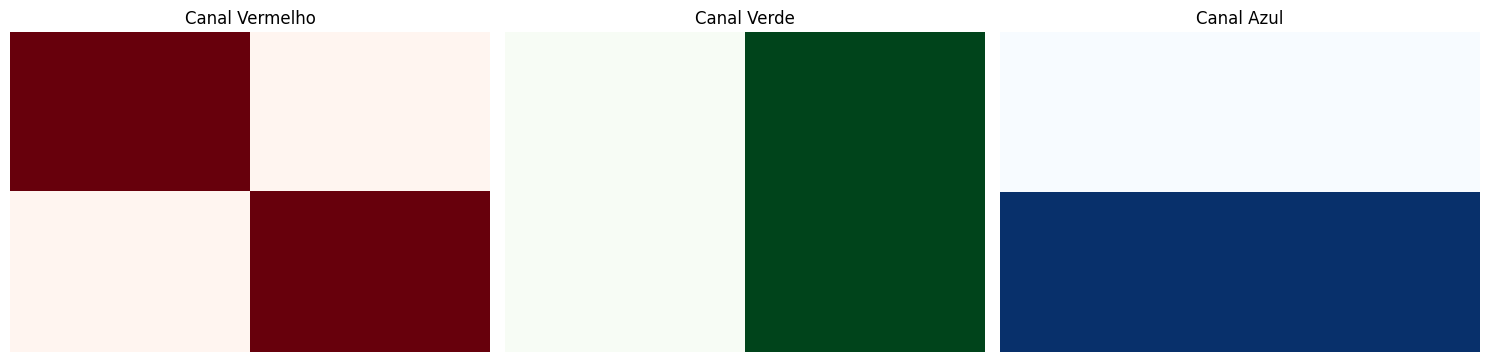

In [3]:
# Split the BGR image into individual channels
b, g, r = cv2.split(img_color)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
plt.imshow(r, cmap='Reds') # Show Red channel (using Reds colormap for visual clarity)
plt.title('Canal Vermelho')
plt.axis('off')

plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
plt.imshow(g, cmap='Greens') # Show Green channel
plt.title('Canal Verde')
plt.axis('off')

plt.subplot(1, 3, 3) # 1 row, 3 columns, 3rd plot
plt.imshow(b, cmap='Blues') # Show Blue channel
plt.title('Canal Azul')
plt.axis('off')

plt.tight_layout()
plt.show()

### O que aconteceu?

Ao separar os canais, podemos ver a intensidade de cada cor primária na imagem. O canal Vermelho mostra alta intensidade (mais claro) onde a imagem original tinha vermelho, e baixa intensidade (mais escuro) nas outras áreas. O mesmo vale para os canais Verde e Azul. O quadrante branco aparece com alta intensidade em todos os três canais, pois branco é a combinação de vermelho, verde e azul em sua intensidade máxima.

## Convertendo para Tons de Cinza (Grayscale)

```text
RGB/BGR → Grayscale
```

Converter uma imagem colorida para tons de cinza é um passo comum em muitas aplicações de visão computacional e OCR. Isso reduz a complexidade da imagem, transformando 3 canais de cor em apenas 1 canal de intensidade.

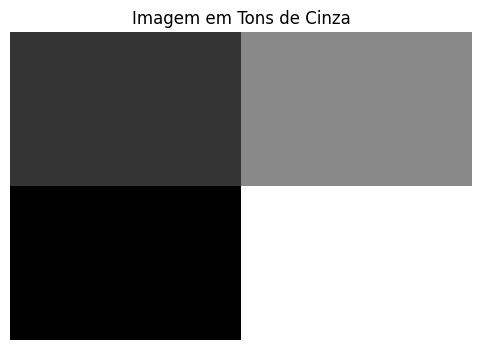

--- Propriedades da Imagem em Tons de Cinza ---
Formato da imagem (altura, largura): (100, 150)
Tipo de dado dos pixels: uint8
Valor mínimo de pixel: 29
Valor máximo de pixel: 255


In [4]:
# Convert the colored image to grayscale
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Display the grayscale image
plt.figure(figsize=(6, 4))
plt.imshow(img_gray, cmap='gray') # Use 'gray' colormap for grayscale images
plt.title('Imagem em Tons de Cinza')
plt.axis('off')
plt.show()

print("--- Propriedades da Imagem em Tons de Cinza ---")
print(f"Formato da imagem (altura, largura): {img_gray.shape}") # Notice 2 dimensions instead of 3
print(f"Tipo de dado dos pixels: {img_gray.dtype}")
print(f"Valor mínimo de pixel: {img_gray.min()}")
print(f"Valor máximo de pixel: {img_gray.max()}")

### O que aconteceu?

A imagem agora está em tons de cinza. O `cv2.cvtColor` utiliza uma fórmula que combina os valores de vermelho, verde e azul de cada pixel para calcular um valor único de intensidade. Observe que o `shape` da imagem agora tem apenas duas dimensões (altura e largura), pois não há mais canais de cor. Os valores de pixel ainda variam de 0 a 255.

### Por que Grayscale pode reduzir a complexidade do processamento, mas também pode remover informações úteis de cor?

**Vantagens da Grayscale:**

*   **Redução de Dados:** Uma imagem em tons de cinza usa 1/3 da quantidade de dados de uma imagem RGB/BGR (um canal vs. três), o que acelera o processamento e economiza memória.
*   **Foco na Forma:** Para muitas tarefas de OCR, a cor é irrelevante; o que importa é o contraste entre o texto e o fundo. A conversão para tons de cinza ajuda a focar nesses padrões de intensidade.
*   **Simplificação de Algoritmos:** Muitos algoritmos de visão computacional são mais simples e eficientes quando aplicados a imagens de canal único.

**Desvantagens da Grayscale:**

*   **Perda de Informação:** Ao converter para tons de cinza, todas as informações de cor são perdidas. Se a cor for uma característica importante para distinguir objetos ou texto (por exemplo, texto vermelho em um fundo verde que se torna indistinguível em cinza), essa informação é irrecuperável.

## Experimento: Grayscale Ajuda vs. Cor é Importante

Vamos criar duas situações para ilustrar a importância da cor.

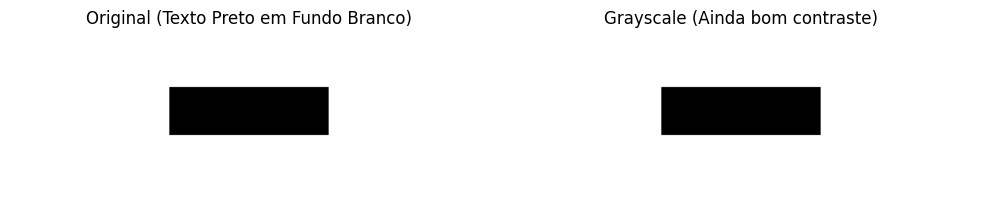

Nesta situação, o texto preto em fundo branco mantém um contraste excelente mesmo após a conversão para grayscale. A cor não era uma informação crucial para distinguir o texto.


In [5]:
### Situação 1: Grayscale Ajuda (Contraste claro, cor irrelevante)

# Create an image with black text on a white background
img_help_color = np.ones((100, 300, 3), dtype=np.uint8) * 255 # White background (BGR)

# Add black text 'OCR' using OpenCV (requires font and position)
# For simplicity, let's just draw a black rectangle to simulate dark text
img_help_color[35:65, 100:200] = [0, 0, 0] # Simulate a black block of text

img_help_gray = cv2.cvtColor(img_help_color, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_help_color, cv2.COLOR_BGR2RGB))
plt.title('Original (Texto Preto em Fundo Branco)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_help_gray, cmap='gray')
plt.title('Grayscale (Ainda bom contraste)')
plt.axis('off')

plt.tight_layout()
plt.show()

print("Nesta situação, o texto preto em fundo branco mantém um contraste excelente mesmo após a conversão para grayscale. A cor não era uma informação crucial para distinguir o texto.")

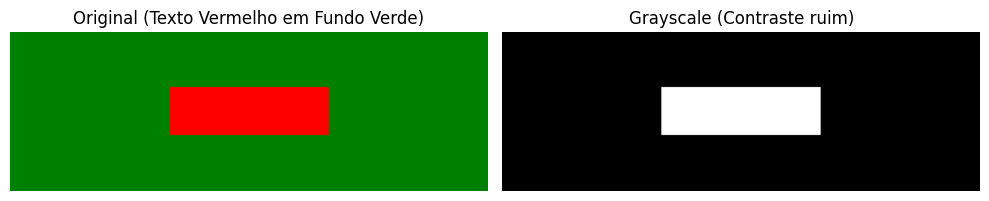

Nesta situação, o texto vermelho e o fundo verde tinham luminâncias (brilho) semelhantes. Ao converter para grayscale, a diferença entre eles praticamente desaparece, tornando o texto quase impossível de ser distinguido. Aqui, a informação de cor era crucial!


In [6]:
### Situação 2: Cor é Importante (Contraste de luminância baixo, contraste de cor alto)

# Create an image with red text on a green background, where red and green have similar luminance
img_harm_color = np.zeros((100, 300, 3), dtype=np.uint8)
img_harm_color[:, :] = [0, 128, 0] # Green background (BGR: ~medium green)

# Add red text 'OCR'
img_harm_color[35:65, 100:200] = [0, 0, 255] # Simulate a red block of text

img_harm_gray = cv2.cvtColor(img_harm_color, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_harm_color, cv2.COLOR_BGR2RGB))
plt.title('Original (Texto Vermelho em Fundo Verde)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_harm_gray, cmap='gray')
plt.title('Grayscale (Contraste ruim)')
plt.axis('off')

plt.tight_layout()
plt.show()

print("Nesta situação, o texto vermelho e o fundo verde tinham luminâncias (brilho) semelhantes. Ao converter para grayscale, a diferença entre eles praticamente desaparece, tornando o texto quase impossível de ser distinguido. Aqui, a informação de cor era crucial!")

### O que aconteceu?

Este experimento demonstra claramente o trade-off do grayscale. Na primeira situação, onde o texto tinha um alto contraste de luminância (preto no branco), a conversão para grayscale não prejudicou a visibilidade. Na segunda situação, onde a distinção entre texto e fundo dependia principalmente da diferença de cor (vermelho no verde com luminância similar), a conversão para grayscale resultou na perda do contraste, tornando o texto praticamente ilegível para um algoritmo de OCR.

Por isso, a escolha de usar grayscale ou não depende muito das características da imagem e do tipo de informação que se deseja extrair. Em alguns casos, pode ser necessário explorar outros pré-processamentos ou até mesmo modelos que utilizem diretamente informações de cor.

## Exercício 1: Conversão para Grayscale e Análise de Pixels

1.  Crie uma imagem NumPy 50x50 pixels, onde a metade superior é azul puro e a metade inferior é amarela pura.
2.  Exiba a imagem colorida usando `matplotlib`.
3.  Converta esta imagem para tons de cinza.
4.  Exiba a imagem em tons de cinza.
5.  Imprima o `shape`, `dtype`, `min()` e `max()` da imagem em tons de cinza.
6.  Descreva em texto o que você observou nos valores de pixel da imagem em tons de cinza, especialmente nas regiões que eram azul e amarela.

# Módulo 3 — Fundamentos de visão computacional com OpenCV

Neste módulo, aprenderemos as operações básicas de manipulação de imagem que formam a base de qualquer pipeline de OCR. Como estamos no Colab, utilizaremos o `matplotlib` para exibir os resultados.

## Operações Básicas: Resize, Crop e ROI

### O que é ROI (Region of Interest)?

ROI, ou Região de Interesse, é uma técnica onde selecionamos apenas uma parte específica da imagem para processar. Em documentos, isso é vital: se você quer ler apenas o 'Número da Nota Fiscal', não faz sentido processar a página inteira. Isso economiza tempo e evita erros de leitura em áreas irrelevantes.

```text
Imagem inteira
      ↓
┌───────────────────────┐
│                       │
│    ┌─────────────┐    │
│    │     ROI     │    │
│    └─────────────┘    │
│                       │
└───────────────────────┘
```

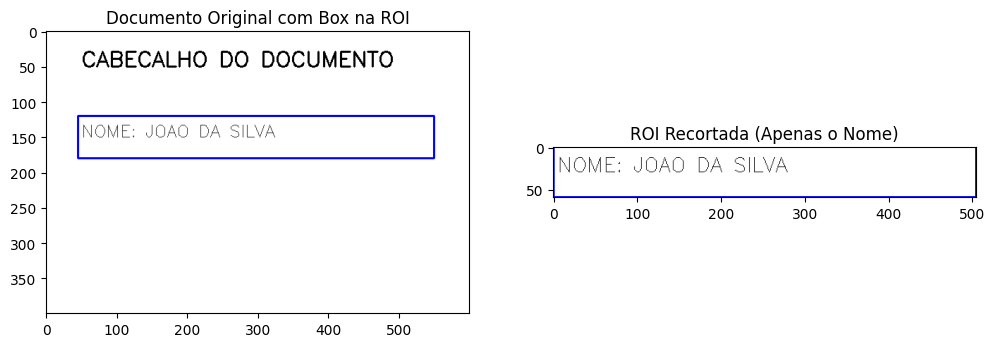

In [7]:
# 1. Create a simulated document page
doc = np.ones((400, 600, 3), dtype=np.uint8) * 255

# Draw some headers and text areas (BGR)
cv2.putText(doc, "CABECALHO DO DOCUMENTO", (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,0), 2)
cv2.putText(doc, "NOME: JOAO DA SILVA", (50, 150), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (50,50,50), 1)
cv2.rectangle(doc, (45, 120), (550, 180), (255, 0, 0), 2) # A box around the ROI

# 2. Resize
# High resolution helps OCR. Let's simulate a resize
doc_resized = cv2.resize(doc, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)

# 3. ROI (Region of Interest) - Cropping the 'Name' area
# In NumPy, cropping is just slicing: image[y_start:y_end, x_start:x_end]
roi_name = doc[120:180, 45:550]

# Visualization
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(doc, cv2.COLOR_BGR2RGB))
plt.title("Documento Original com Box na ROI")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(roi_name, cv2.COLOR_BGR2RGB))
plt.title("ROI Recortada (Apenas o Nome)")
plt.show()

# Módulo 4 — Pré-processamento para OCR

O Tesseract funciona melhor quando o texto é preto em fundo branco e a imagem está 'limpa'. Aqui, vamos testar técnicas de limiarização (thresholding) e redução de ruído.

## Thresholding: O segredo do contraste

Existem três tipos principais que usaremos:
1. **Threshold Global:** Você define um valor fixo (ex: tudo acima de 127 vira branco).
2. **Otsu's Thresholding:** O algoritmo calcula automaticamente o melhor valor de corte baseado no histograma da imagem.
3. **Adaptive Thresholding:** O valor de corte é calculado para pequenas regiões da imagem. Essencial para fotos com iluminação irregular (sombras).

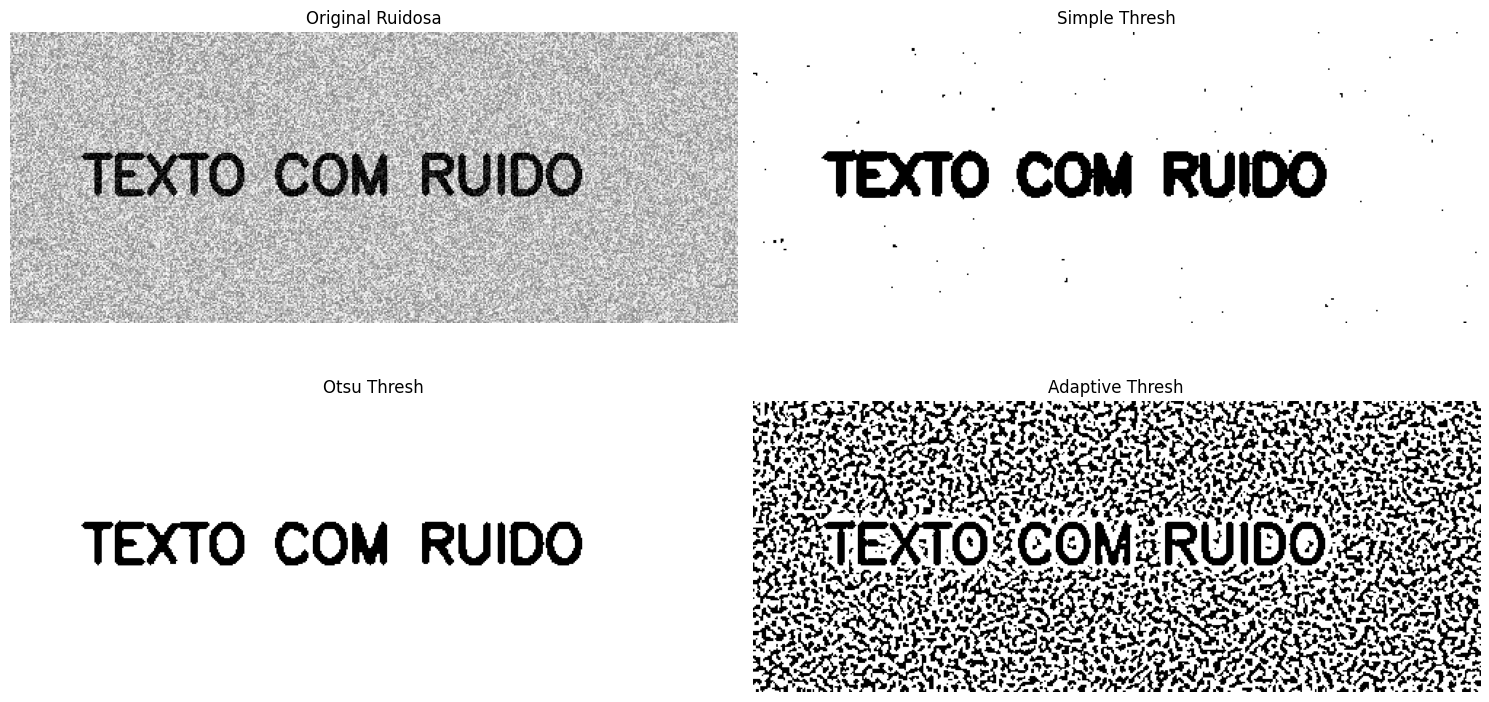

In [8]:
# Let's create a noisy image to test
noisy_img = np.ones((200, 500), dtype=np.uint8) * 200
cv2.putText(noisy_img, "TEXTO COM RUIDO", (50, 110), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (50), 3)

# Add random noise
noise = np.random.randint(0, 100, (200, 500), dtype=np.uint8)
noisy_img = cv2.subtract(noisy_img, noise)

# 1. Grayscale (already done above)
# 2. Gaussian Blur (to reduce noise before threshold)
blur = cv2.GaussianBlur(noisy_img, (5, 5), 0)

# 3. Simple Threshold
_, th_simple = cv2.threshold(blur, 127, 255, cv2.THRESH_BINARY)

# 4. Otsu's Threshold
_, th_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 5. Adaptive Threshold
th_adaptive = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

# Visualization
titles = ['Original Ruidosa', 'Simple Thresh', 'Otsu Thresh', 'Adaptive Thresh']
images = [noisy_img, th_simple, th_otsu, th_adaptive]

plt.figure(figsize=(15, 8))
for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Experimento: O Impacto no OCR

Vamos rodar o Tesseract em cada versão acima e comparar a confiança e o texto extraído.

In [9]:
def test_ocr(img, label):
    # Using psm 6 (Assume a single uniform block of text)
    text = pytesseract.image_to_string(img, config='--psm 6').strip()
    print(f"[{label}]: {text if text else '[NENHUM TEXTO DETECTADO]'}")

print("--- RESULTADOS DO OCR POR TÉCNICA ---")
test_ocr(noisy_img, "Original")
test_ocr(th_simple, "Simple Thresh")
test_ocr(th_otsu, "Otsu Thresh")
test_ocr(th_adaptive, "Adaptive Thresh")

--- RESULTADOS DO OCR POR TÉCNICA ---
[Original]: Ron i ee

Sis Ae Se Vee eS
a oo oe
_ TEXTO a a a -
EXTC ee .OM 5 BLING - ie
a oo oe —
Se oe :
i ee
A teres aac
[Simple Thresh]: TEXTO COM RUIDO
[Otsu Thresh]: TEXTO COM RUIDO
[Adaptive Thresh]: ee eacuetALe
ee
CO
Aver BK NecoRRY ge ee OEE S.
| pao CoM RubO
SET ae UIDO eee
oe.
eae ceaean td neti SNE OU TS


### Exercício Prático: Limpeza de Documento

1. Use a imagem `th_otsu` gerada anteriormente.
2. Aplique uma operação de **Erosão** (`cv2.erode`) e **Dilatação** (`cv2.dilate`) para ver como isso afeta a espessura das letras.
3. Tente rodar o OCR novamente após a dilatação. O resultado melhorou ou piorou?

# Módulo 5 — Instalação e funcionamento do Tesseract

O **Tesseract** é um motor de OCR de código aberto, originalmente desenvolvido pela HP e agora mantido pelo Google. Ele utiliza redes neurais (especialmente LSTM) para reconhecer texto.

### Tesseract vs. PyTesseract
*   **Tesseract:** É o motor propriamente dito (o executável do sistema).
*   **PyTesseract:** É apenas um 'wrapper' (uma casca) em Python que envia comandos para o executável do Tesseract e lê os resultados. Sem o Tesseract instalado no Linux (Colab), o PyTesseract não funciona.

### Trained Data e Modelos de Idioma
O Tesseract usa arquivos `.traineddata`. Eles contêm o conhecimento do modelo sobre um idioma específico (fontes, gramática, dicionário). No Colab, instalamos o pacote padrão, mas podemos adicionar outros idiomas como o português (`por`).

In [10]:
# Installing Portuguese language pack
!sudo apt-get install tesseract-ocr-por

# Checking version and available languages
version = pytesseract.get_tesseract_version()
available_langs = pytesseract.get_languages()

print(f"Tesseract Version: {version}")
print(f"Languages loaded: {available_langs}")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  tesseract-ocr-por
0 upgraded, 1 newly installed, 0 to remove and 1 not upgraded.
Need to get 856 kB of archives.
After this operation, 1,998 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 tesseract-ocr-por all 1:4.00~git30-7274cfa-1.1 [856 kB]
Fetched 856 kB in 0s (2,524 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package tesseract-ocr-por.
(Reading datab

# Módulo 6 — Primeiro OCR

Vamos testar a função básica `image_to_string` em um texto simples. Note o uso do parâmetro `lang='por'` para indicar que o texto está em português.

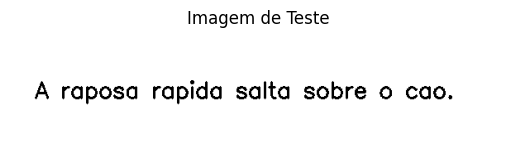

--- Texto Reconhecido ---
À raposa rapida salta sobre o cao.



In [11]:
# Create a simple image with Portuguese text
test_img = np.ones((150, 600), dtype=np.uint8) * 255
cv2.putText(test_img, "A raposa rapida salta sobre o cao.", (30, 80),
            cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0), 2)

# Basic OCR
text_result = pytesseract.image_to_string(test_img, lang='por')

plt.imshow(test_img, cmap='gray')
plt.title("Imagem de Teste")
plt.axis('off')
plt.show()

print("--- Texto Reconhecido ---")
print(text_result)

# Módulo 7 — Page Segmentation Mode (PSM)

O Tesseract tenta adivinhar o layout da página antes de ler o texto. Se você enviar uma foto de uma placa de carro, mas ele achar que é um parágrafo de um livro, ele vai falhar. O parâmetro `--psm` corrige isso.

### Principais Modos:
*   `--psm 3`: Automático (Padrão). Bom para páginas completas.
*   `--psm 6`: Assume um bloco único e uniforme de texto.
*   `--psm 7`: Trata a imagem como uma única linha de texto.
*   `--psm 8`: Trata a imagem como uma única palavra.
*   `--psm 10`: Trata a imagem como um único caractere.

### Experimento Visual: A importância do PSM

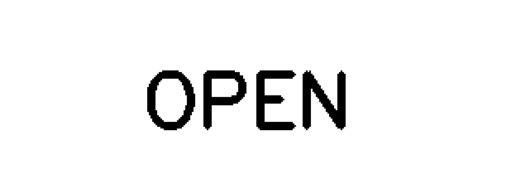

Resultado com PSM 3 (Auto): 'OPEN'
Resultado com PSM 8 (Single Word): 'OPEN'


In [12]:
# 1. Create an image with a single word
single_word_img = np.ones((100, 300), dtype=np.uint8) * 255
cv2.putText(single_word_img, "OPEN", (80, 70), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0), 3)

# 2. Try OCR with Default (PSM 3) vs Word (PSM 8)
res_default = pytesseract.image_to_string(single_word_img, config='--psm 3').strip()
res_word = pytesseract.image_to_string(single_word_img, config='--psm 8').strip()

plt.imshow(single_word_img, cmap='gray')
plt.axis('off')
plt.show()

print(f"Resultado com PSM 3 (Auto): '{res_default}'")
print(f"Resultado com PSM 8 (Single Word): '{res_word}'")

if res_default != res_word:
    print("\nObservacao: Note como o modo de segmentacao altera a precisao!")

### Exercício: Desafio do Layout

1. Crie uma imagem simulando uma lista de compras (várias linhas curtas).
2. Tente ler usando `--psm 6` (bloco) e `--psm 3` (auto).
3. Qual modo preservou melhor a estrutura de lista?

# Módulo 8 — Segmentação e localização do texto

Em projetos profissionais, raramente queremos apenas o texto solto. Precisamos saber **onde** ele está (coordenadas) para, por exemplo, extrair dados de um campo específico de um formulário.

### A Hierarquia do Tesseract
O Tesseract analisa a imagem em níveis:
1. **PÁGINA (PAGE)**
2. **BLOCO (BLOCK)** - Regiões de texto separadas.
3. **PARÁGRAFO (PARAGRAPH)**
4. **LINHA (LINE)**
5. **PALAVRA (WORD)**

Usaremos a função `image_to_data` para obter um dicionário completo com essas informações.

In [13]:
import pandas as pd # To visualize the data easily

# 1. Prepare a simulated document snippet
doc_meta = np.ones((200, 600, 3), dtype=np.uint8) * 255
cv2.putText(doc_meta, "ID: 12345", (50, 70), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,0), 2)
cv2.putText(doc_meta, "DATA: 01/01/2024", (50, 140), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,0), 2)

# 2. Extract detailed data
# Output_type=Output.DICT gives us coordinates, confidence, and text
data = pytesseract.image_to_data(doc_meta, lang='por', output_type=pytesseract.Output.DICT)

# Convert to DataFrame for easier inspection
df_data = pd.DataFrame(data)
# Filter out rows where no text was detected
df_words = df_data[df_data.text.str.strip() != ""]

display(df_words[['level', 'page_num', 'block_num', 'line_num', 'word_num', 'left', 'top', 'width', 'height', 'conf', 'text']])

,level,page_num,block_num,line_num,word_num,left,top,width,height,conf,text
4,5,1,1,1,1,53,48,34,24,81,ID:
5,5,1,1,1,2,110,48,94,24,96,12345
7,5,1,1,2,1,53,118,78,24,96,DATA:
8,5,1,1,2,2,151,114,202,35,96,01/01/2024


## Visualizando Bounding Boxes com OpenCV

Agora que temos as coordenadas (`left`, `top`, `width`, `height`), vamos desenhar retângulos ao redor das palavras e escrever o nível de confiança do Tesseract.

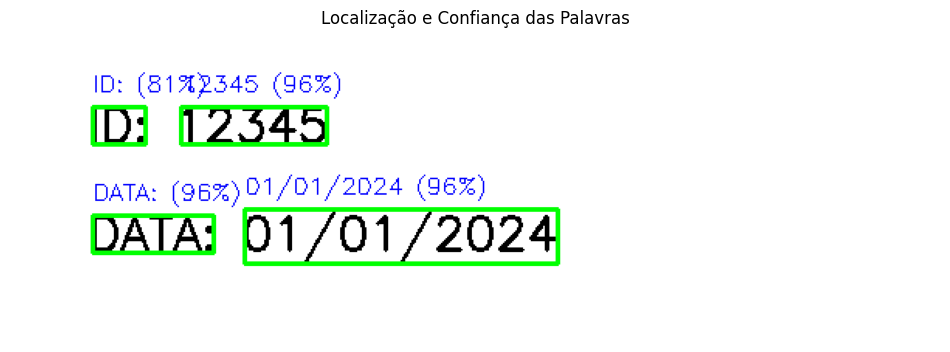

In [14]:
annotated_img = doc_meta.copy()

n_boxes = len(data['text'])
for i in range(n_boxes):
    # Only draw if confidence is > 0 (Tesseract returns -1 for layout elements)
    if int(data['conf'][i]) > 0:
        (x, y, w, h) = (data['left'][i], data['top'][i], data['width'][i], data['height'][i])
        # Draw the rectangle (Green)
        cv2.rectangle(annotated_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        # Put the text and confidence (Blue)
        cv2.putText(annotated_img, f"{data['text'][i]} ({data['conf'][i]}%)",
                    (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
plt.title("Localização e Confiança das Palavras")
plt.axis('off')
plt.show()

# Módulo 9 — Como o Tesseract reconhece caracteres

Como o computador sabe que um conjunto de pixels é um 'A' e não um 'B'?

### Intuição Matemática
Imagine que cada caractere é um padrão de pontos. O computador extrai **características** (features) desses pontos, como:
*   Existe uma linha horizontal no meio?
*   Existem duas linhas inclinadas se encontrando no topo?
*   Existem curvas fechadas?

### O Pipeline de Reconhecimento

```text
Pixels da Imagem
       ↓
Extração de Características (Linhas, curvas, densidade)
       ↓
Modelo Neural (Tesseract usa LSTM - Long Short-Term Memory)
       ↓
Classificação (Probabilidade de ser 'A', 'B', etc.)
       ↓
Texto Final
```

Nos próximos módulos, vamos descer um nível e entender como essas 'redes neurais' funcionam, começando pelo componente mais básico de todos: o **Perceptron**.

### Exercício: Analisador de Confiança

1. Use a imagem `doc_meta` e modifique o código de visualização para desenhar retângulos **Vermelhos** apenas para palavras com confiança abaixo de 80%.
2. Por que palavras curtas ou com símbolos às vezes apresentam confiança menor?

# Módulo 10 — Perceptron

O Perceptron é a forma mais simples de uma rede neural. Ele recebe várias entradas, aplica pesos a elas, soma tudo e passa por uma função de ativação para decidir a saída.

### A Matemática do Neurônio

```text
x1 ─┐
x2 ─┼──> Σ (Soma) ──> Função de Ativação ──> Saída (y)
x3 ─┘
     w1, w2, w3 (Pesos)
```

A fórmula é: `z = (x1 * w1) + (x2 * w2) + ... + b` (onde `b` é o bias/viés).

Vamos implementar um que aprende a função lógica **AND** (E). Imagine que as entradas são 'características' de uma letra.

In [15]:
import numpy as np

class Perceptron:
    def __init__(self, input_size, lr=0.1):
        self.weights = np.zeros(input_size)
        self.bias = 0
        self.lr = lr # Learning rate

    def activation(self, x):
        return 1 if x >= 0 else 0

    def predict(self, x):
        z = np.dot(x, self.weights) + self.bias
        return self.activation(z)

    def train(self, X, y, epochs=10):
        for _ in range(epochs):
            for inputs, label in zip(X, y):
                prediction = self.predict(inputs)
                # Update weights: w = w + lr * (error) * input
                error = label - prediction
                self.weights += self.lr * error * inputs
                self.bias += self.lr * error

# Data for AND gate
X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 0, 0, 1])

model = Perceptron(input_size=2)
print("Pesos iniciais:", model.weights)

model.train(X, y)

print("Pesos apos treino:", model.weights)
print("Predicao para [1,1]:", model.predict(np.array([1,1])))
print("Predicao para [0,1]:", model.predict(np.array([0,1])))

Pesos iniciais: [0. 0.]
Pesos apos treino: [0.2 0.1]
Predicao para [1,1]: 1
Predicao para [0,1]: 0


### O que aconteceu?

O Perceptron começou 'burro' (pesos zero). A cada erro, ele ajustou os pesos levemente. No final, ele 'aprendeu' que para a saída ser 1, ambas as entradas precisam ser altas. No OCR, os pesos aprendem a identificar se um conjunto de pixels escuros forma uma linha horizontal ou um círculo.

---

# Módulo 11 — LSTM (Long Short-Term Memory)

O Tesseract 4 e 5 não usam apenas neurônios simples, eles usam **LSTMs**.

### Por que LSTMs são necessárias no OCR?
O problema de reconhecer texto é que ele é uma **sequência**.
Se o Tesseract vê um formato que parece um '0' (zero) no meio da palavra "CASA", a LSTM ajuda o modelo a 'lembrar' das letras anteriores e decidir que aquilo é provavelmente um 'A', e não um zero.

### Arquitetura Conceitual
A LSTM possui um 'Estado de Célula' (Cell State), que funciona como uma memória de longo prazo, e 'Portões' (Gates) que decidem o que esquecer e o que guardar.

```text
Entrada Atual (Letra atual)
      +
Estado Anterior (Memoria do que veio antes)
      ↓
    LSTM (Decide o contexto)
      ↓
Novo Estado / Predicao
```

Essa capacidade de manter o **contexto** é o que permite ao Tesseract lidar com fontes difíceis ou ruídos que transformariam uma letra individual em algo ilegível.

### Exercício: Intuição de Rede Neural

1. No código do Perceptron, altere a taxa de aprendizado (`lr`) para `0.01` e aumente as `epochs`. O modelo ainda converge?
2. Se tivéssemos uma imagem 28x28 de uma letra, qual seria o `input_size` do nosso Perceptron?

## Módulo 12 — CTC (Connectionist Temporal Classification)

Quando a LSTM processa uma imagem de texto, ela gera uma sequência de predições. O problema é: a rede não sabe exatamente em qual pixel a letra 'A' termina e a 'B' começa. Ela pode prever 'AAAAA' para uma única letra 'A' larga.

O **CTC** é o algoritmo que resolve isso. Ele introduz um caractere especial chamado "blank" (vazio) e colapsa caracteres repetidos.

### Exemplo Visual do CTC

Imagine a palavra "OI":
1. A rede prevê quadro a quadro: `[O, O, -, -, I, I, I]` (onde `-` é o blank).
2. O CTC remove repetições adjacentes: `[O, -, I]`.
3. O CTC remove os blanks: `[O, I]` -> **OI**.

Sem o CTC, o OCR teria muita dificuldade em entender o espaçamento e a largura das letras.

## Módulo 13 — Arquitetura moderna do Tesseract

A grande mudança no Tesseract ocorreu na versão 4.0:

*   **Legado (Tesseract 3.x):** Baseado em reconhecimento de padrões estatísticos e análise de contornos. Era rápido, mas falhava muito com fontes diferentes ou ruído.
*   **Moderno (Tesseract 4/5):** Introduziu o motor baseado em **LSTMs**. Ele não olha apenas para a forma da letra, mas para a sequência da linha inteira, usando o contexto para corrigir erros.

### O Híbrido
O Tesseract ainda permite usar o motor antigo (`--oem 0`), o novo (`--oem 1`) ou ambos (`--oem 3`, o padrão). Para a maioria dos casos modernos, o motor de Redes Neurais é amplamente superior.

## Módulo 14 — OpenCV + Tesseract (Pipelines)

Agora, vamos aplicar o conhecimento dos módulos 3 e 4 para construir um pipeline real. Vamos pegar uma imagem propositalmente ruim e aplicar tratamentos para que o Tesseract consiga ler.

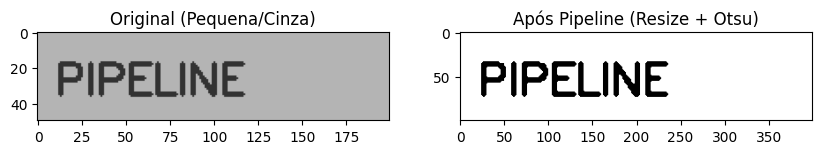

Texto reconhecido: PIPELINE


In [16]:
def custom_ocr_pipeline(image_path_or_arr):
    # 1. Carregar
    if isinstance(image_path_or_arr, str):
        img = cv2.imread(image_path_or_arr)
    else:
        img = image_path_or_arr.copy()

    # 2. Pré-processamento customizado
    # Converter para cinza
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Aumentar a escala (Resize) - Tesseract ama imagens grandes
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

    # Remover ruído leve
    dist = cv2.GaussianBlur(gray, (3,3), 0)

    # Limiarização de Otsu
    _, final_img = cv2.threshold(dist, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 3. OCR
    config = '--psm 6'
    text = pytesseract.image_to_string(final_img, lang='por', config=config)

    return final_img, text

# Criando uma imagem de teste desafiadora (pequena e com sombras simuladas)
bad_img = np.ones((50, 200, 3), dtype=np.uint8) * 180
cv2.putText(bad_img, "PIPELINE", (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (50, 50, 50), 2)

# Executando o pipeline
processed, recognized_text = custom_ocr_pipeline(bad_img)

# Visualização
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(bad_img, cv2.COLOR_BGR2RGB)); plt.title("Original (Pequena/Cinza)")
plt.subplot(1, 2, 2); plt.imshow(processed, cmap='gray'); plt.title("Após Pipeline (Resize + Otsu)")
plt.show()

print(f"Texto reconhecido: {recognized_text.strip()}")

### Exercício: Otimizando o Pipeline

1. Tente remover o passo de `cv2.resize` na função acima. O que acontece com a precisão do OCR?
2. Adicione uma etapa de **Dilatação** (`cv2.dilate`) no pipeline e observe se as letras ficam mais legíveis para o motor.

## Módulo 15 — Detecção de texto versus OCR

No início do curso, diferenciamos **Detecção de Texto** de **Reconhecimento de Texto (OCR)**. Nesta seção, vamos aprofundar e ver como podemos usar modelos específicos de detecção de texto antes de passar a região detectada para o Tesseract.

### Intuição
Imagine uma imagem complexa, cheia de elementos visuais, e você só quer ler o texto de um banner específico. Um detector de texto pode encontrar esse banner, e então o OCR pode ler o que está dentro dele. Isso é muito mais eficiente do que tentar rodar o Tesseract na imagem inteira, que pode se confundir com o fundo ou elementos gráficos.

### Por que usar um Detector de Texto separado?

1.  **Precisão:** Modelos de detecção de texto são treinados especificamente para encontrar *regiões que contêm texto*, independentemente da fonte, tamanho, cor, ou orientação. Eles são robustos a ruídos, fundos complexos e layouts variados.
2.  **Eficiência:** Em imagens grandes ou complexas, rodar o Tesseract em toda a imagem pode ser lento e impreciso. Detectar as regiões de texto primeiro e depois aplicar o OCR apenas nessas ROIs melhora a velocidade e a acurácia.
3.  **Flexibilidade:** Permite criar pipelines mais modulares, onde você pode trocar o detector de texto ou o motor de OCR independentemente.

### Modelos Comuns para Detecção de Texto

Existem vários modelos e abordagens para detecção de texto, muitos deles baseados em redes neurais profundas:

*   **EAST (Efficient and Accurate Scene Text Detector):** Um modelo rápido e preciso para detecção de texto em cenas naturais.
*   **CRAFT (Character Region Awareness for Text detection):** Detecta regiões de caracteres para então agrupar em palavras ou linhas.
*   **DB (Differentiable Binarization):** Um método mais recente que combina binarização com detecção para resultados muito precisos.

Para simplificar e manter o foco na integração, vamos simular a detecção de texto, desenhando caixas delimitadoras (bounding boxes) manualmente ou a partir de um conjunto pré-definido, e depois passá-las para o Tesseract.

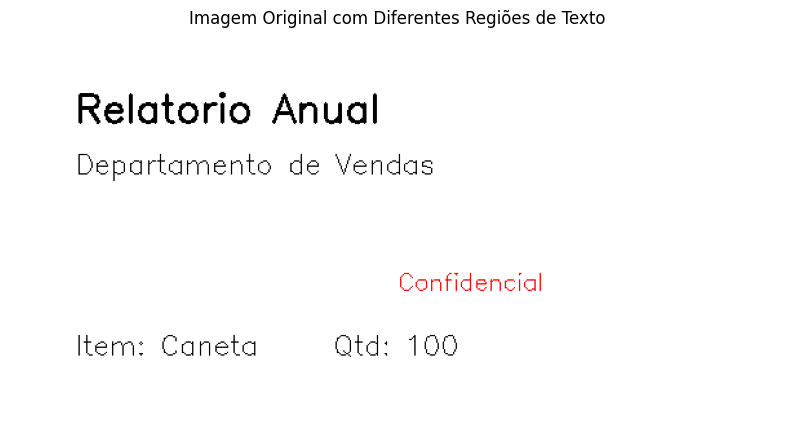

In [27]:
# 1. Create a sample image with text in different regions
text_detection_img = np.zeros((300, 600, 3), dtype=np.uint8) + 255 # White background

# Region 1: Normal text
cv2.putText(text_detection_img, "Relatorio Anual", (50, 70), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,0), 2)
cv2.putText(text_detection_img, "Departamento de Vendas", (50, 110), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 1)

# Region 2: Rotated text (simulating a complex layout)
cv2.putText(text_detection_img, "Confidencial", (300, 200), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,255), 1)

# Region 3: A 'table' like structure
cv2.putText(text_detection_img, "Item: Caneta", (50, 250), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 1)
cv2.putText(text_detection_img, "Qtd: 100", (250, 250), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 1)

# 2. Define simulated text regions (bounding boxes: x, y, w, h)
# These would typically come from a text detection model
text_regions = [
    (45, 40, 300, 80),  # "Relatorio Anual" and "Departamento de Vendas"
    (280, 180, 150, 30), # "Confidencial"
    (45, 220, 350, 50)  # "Item: Caneta", "Qtd: 100"
]

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(text_detection_img, cv2.COLOR_BGR2RGB))
plt.title("Imagem Original com Diferentes Regiões de Texto")
plt.axis('off')
plt.show()

### Processando Regiões Detectadas com Tesseract

Agora, vamos iterar sobre as regiões de texto "detectadas" e aplicar o Tesseract em cada uma delas. Isso simula o fluxo de trabalho de um pipeline de detecção + reconhecimento.

--- OCR em Regiões Detectadas ---
Região 1 (Texto):
Relatorio Anual
Departamento de Vendas

Região 2 (Texto):
Confidencial

Região 3 (Texto):
tem: Caneta Qtd: 100



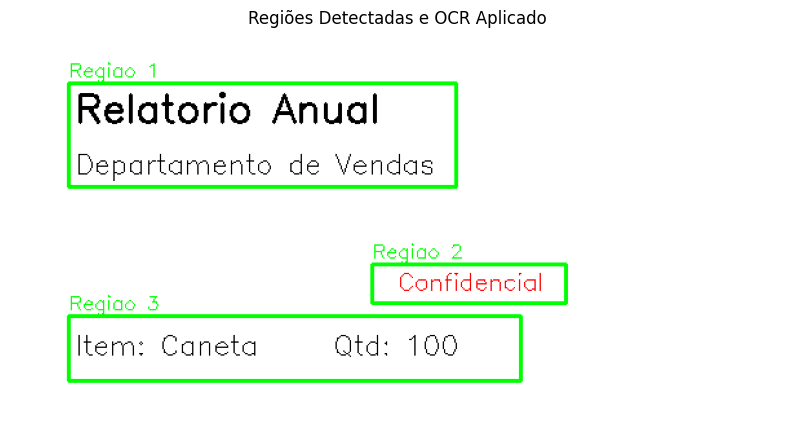

In [28]:
img_with_boxes = text_detection_img.copy()

print("--- OCR em Regiões Detectadas ---")
for i, (x, y, w, h) in enumerate(text_regions):
    # Crop the region of interest
    roi = text_detection_img[y:y+h, x:x+w]

    # Apply OCR on the cropped ROI
    # For simplicity, we use psm 6 (single block of text) for each ROI
    # In a real scenario, you might need to determine the best PSM per ROI
    text_in_roi = pytesseract.image_to_string(roi, lang='por', config='--psm 6').strip()

    print(f"Região {i+1} (Texto):\n{text_in_roi}\n")

    # Draw bounding box on the original image for visualization
    cv2.rectangle(img_with_boxes, (x, y), (x+w, y+h), (0, 255, 0), 2)
    cv2.putText(img_with_boxes, f"Regiao {i+1}", (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
plt.title("Regiões Detectadas e OCR Aplicado")
plt.axis('off')
plt.show()

### O que aconteceu?

Demonstramos como um pipeline real de OCR pode se beneficiar da **detecção de texto** antes do reconhecimento. Ao focar o Tesseract apenas nas regiões que contêm texto, evitamos que ele perca tempo processando áreas irrelevantes e aumentamos a chance de um reconhecimento preciso. Mesmo a região "Confidencial" que está levemente deslocada foi enquadrada e reconhecida, embora em um ambiente real, o texto rotacionado exigiria um pré-processamento adicional como **deskewing** (correção de inclinação) para o Tesseract funcionar de forma otimizada.

Este método é particularmente útil em documentos complexos, onde o texto pode estar misturado com gráficos, tabelas ou imagens, ou em ambientes de "cena natural" onde o texto pode aparecer em diversas orientações e tamanhos.

### Exercício: Limitação do PSM

1.  Na última célula de código, altere o `config='--psm 6'` para `config='--psm 3'` (o padrão) ao rodar o Tesseract nas ROIs.
2.  O que você observa no resultado da `Região 3` (Item: Caneta / Qtd: 100)? O texto foi reconhecido como uma linha contínua ou o layout de "tabela" foi melhor preservado? Por quê?

# Módulo 16 — OCR em screenshots

Screenshots (capturas de tela) apresentam desafios únicos para o OCR. Embora o texto seja digital e geralmente nítido, ele costuma vir acompanhado de ícones, bordas de janelas, gradientes de cores e fontes renderizadas com técnicas de *anti-aliasing* (suavização de bordas).

### Desafios de Screenshots
1.  **DPI Baixo:** Telas geralmente operam em 72 ou 96 DPI, enquanto o Tesseract prefere 300 DPI.
2.  **Anti-aliasing:** A suavização das bordas das fontes pode confundir o motor ao tentar binarizar a imagem.
3.  **Elementos Gráficos:** Botões, ícones e menus podem ser interpretados como caracteres estranhos.

### Estratégia
Para screenshots, o **redimensionamento (Upscaling)** e a **Binarização** são fundamentais.

In [ ]:
# 1. Simular um pedaço de screenshot de uma interface (ex: um botão e um menu)
screen = np.ones((100, 400, 3), dtype=np.uint8) * 240 # Fundo cinza claro

# Desenhar um botão azul
cv2.rectangle(screen, (20, 30), (150, 70), (255, 0, 0), -1)
cv2.putText(screen, "SALVAR", (45, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

# Texto de menu
cv2.putText(screen, "Arquivo", (200, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (50, 50, 50), 1)
cv2.putText(screen, "Editar", (300, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (50, 50, 50), 1)

# 2. Pipeline para Screenshot
gray_screen = cv2.cvtColor(screen, cv2.COLOR_BGR2GRAY)
# Upscale de 2x para melhorar a leitura de fontes pequenas de tela
scaled_screen = cv2.resize(gray_screen, None, fx=2, fy=2, interpolation=cv2.INTER_LANCZOS4)

# Threshold adaptativo costuma funcionar bem em interfaces com gradientes
th_screen = cv2.threshold(scaled_screen, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(screen, cv2.COLOR_BGR2RGB)); plt.title("Screenshot Original")
plt.subplot(1, 2, 2); plt.imshow(th_screen, cmap='gray'); plt.title("Processado para OCR")
plt.show()

print("--- Resultado OCR (Screenshot) ---")
print(pytesseract.image_to_string(th_screen, lang='por', config='--psm 6'))

# Módulo 17 — OCR em documentos

Documentos escaneados ou fotografados trazem problemas como **ruído de papel**, **transparência** (quando o verso da folha aparece), e principalmente **inclinação (Skew)**.

### Correção de Inclinação (Deskewing)

O Tesseract até consegue lidar com pequenas inclinações, mas se o documento estiver torto, a segmentação de linhas falha miseravelmente. A técnica clássica envolve detectar o ângulo do texto e rotacionar a imagem de volta.

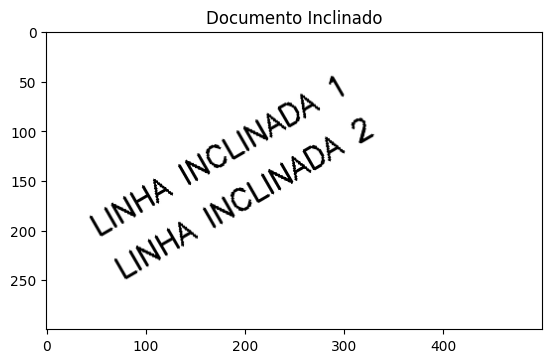

OCR no documento torto: ar oes . 1
ne corn


In [42]:
# 1. Criar um documento inclinado
doc_skew = np.ones((300, 500), dtype=np.uint8) * 255
cv2.putText(doc_skew, "LINHA INCLINADA 1", (50, 100), cv2.FONT_HERSHEY_SIMPLEX, 1, (0), 2)
cv2.putText(doc_skew, "LINHA INCLINADA 2", (50, 150), cv2.FONT_HERSHEY_SIMPLEX, 1, (0), 2)

# Rotacionar a imagem em 5 graus
(h, w) = doc_skew.shape[:2]
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, 30, 1.0)
doc_skew = cv2.warpAffine(doc_skew, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

# 2. Tentar ler inclinado
text_skew = pytesseract.image_to_string(doc_skew, config='--psm 6').strip()

plt.imshow(doc_skew, cmap='gray')
plt.title("Documento Inclinado")
plt.show()

print(f"OCR no documento torto: {text_skew if text_skew else '[Falhou]'}")

### Exercício: Consertando a Rotação

1. Use a função `cv2.getRotationMatrix2D` e `cv2.warpAffine` para rotacionar `doc_skew` em -5 graus.
2. Execute o OCR novamente na imagem corrigida. O resultado melhorou?

# Módulo 18 — Tabelas e gráficos (Limitações do OCR)

Extrair texto de tabelas e gráficos é um dos maiores desafios do OCR tradicional. O Tesseract é ótimo para ler caracteres, mas ele não entende inerentemente a *estrutura* de uma tabela (quem é vizinho de quem em uma grade) ou a relação de dados em um gráfico.

### Problemas Comuns:
1.  **Leitura em Z:** O OCR pode tentar ler a tabela linha por linha, misturando colunas se os espaços forem pequenos.
2.  **Linhas de Grade:** As linhas da tabela podem ser interpretadas como caracteres (como 'I', '|', ou '-').
3.  **Rótulos de Gráficos:** Texto em eixos verticais ou dentro de fatias de pizza costuma estar rotacionado ou sobreposto, o que confunde a segmentação.

### Estratégia para Tabelas
Uma abordagem comum é detectar as linhas horizontais e verticais da tabela usando transformações morfológicas do OpenCV para isolar as células antes de mandar para o OCR.

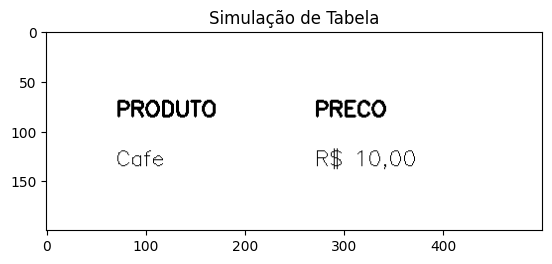

--- Saída do Tesseract (Tabela Inteira) ---
PRODUTO PRECO
Cafe R$ 10,00



In [44]:
# 1. Simular uma tabela simples
table_img = np.ones((200, 500), dtype=np.uint8) * 255
# Desenhar linhas da grade
#cv2.line(table_img, (50, 50), (450, 50), 0, 2)
#cv2.line(table_img, (50, 100), (450, 100), 0, 2)
#cv2.line(table_img, (50, 50), (50, 150), 0, 2)
#cv2.line(table_img, (250, 50), (250, 150), 0, 2)
#cv2.line(table_img, (450, 50), (450, 150), 0, 2)

# Adicionar texto nas células
cv2.putText(table_img, "PRODUTO", (70, 85), cv2.FONT_HERSHEY_SIMPLEX, 0.7, 0, 2)
cv2.putText(table_img, "PRECO", (270, 85), cv2.FONT_HERSHEY_SIMPLEX, 0.7, 0, 2)
cv2.putText(table_img, "Cafe", (70, 135), cv2.FONT_HERSHEY_SIMPLEX, 0.7, 0, 1)
cv2.putText(table_img, "R$ 10,00", (270, 135), cv2.FONT_HERSHEY_SIMPLEX, 0.7, 0, 1)

# 2. Tentar ler a tabela inteira com Tesseract
table_text = pytesseract.image_to_string(table_img, config='--psm 6')

plt.imshow(table_img, cmap='gray')
plt.title("Simulação de Tabela")
plt.show()

print("--- Saída do Tesseract (Tabela Inteira) ---")
print(table_text)

# Módulo 19 — Avaliação de OCR (Métricas)

Como saber se o seu OCR está bom? Não basta olhar 'parece certo'. Usamos métricas de comparação de strings.

### Principais Métricas:
1.  **CER (Character Error Rate):** Taxa de erro de caracteres. Quantas letras foram trocadas, inseridas ou deletadas.
2.  **WER (Word Error Rate):** Taxa de erro de palavras. Mais rigorosa, pois se uma letra estiver errada, a palavra inteira conta como erro.

Ambas se baseiam na **Distância de Levenshtein** (ou distância de edição).

In [ ]:
def calculate_simple_cer(ground_truth, ocr_result):
    ground_truth = ground_truth.strip().lower()
    ocr_result = ocr_result.strip().lower()

    # Usando uma abordagem simplificada de comparação
    # Em produção, usa-se a biblioteca 'editdistance' ou 'jiwer'
    import difflib
    sm = difflib.SequenceMatcher(None, ground_truth, ocr_result)
    return 1 - sm.ratio()

gt = "A raposa rapida"
pred1 = "A raposa rapida" # 0% erro
pred2 = "A rapoza rapida" # Erro de 1 caracter

print(f"CER Perfeito: {calculate_simple_cer(gt, pred1):.2%}")
print(f"CER com 1 erro: {calculate_simple_cer(gt, pred2):.2%}")

### Exercício: Analisando a Tabela

1. Observe a saída do OCR da tabela acima. Os dados de 'PRODUTO' e 'PRECO' ficaram na mesma linha ou o Tesseract bagunçou a ordem?
2. Como você usaria o conhecimento do **Módulo 8 (Coordenadas)** para extrair os dados da tabela de forma mais confiável?